# EDA 01 – surová data z TMDB (měsíční běh `full`)

Jednoduchý průzkum dat z Cloud Run Jobu `films-scraper`: top 10k, kina US/CZ a novinky z 23 zemí.
Data: `data/raw/tmdb/mode=full/run=…/` (staženo z `gs://films-512811-raw/tmdb/`).

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 60)

RUN = sorted(Path("../data/raw/tmdb/mode=full").glob("run=*"))[-1]   # nejnovější běh
manifest = json.loads((RUN / "manifest.json").read_text(encoding="utf-8"))
print("run:", RUN.name, "| doba:", manifest["duration_s"], "s | filmů:", manifest["unique_movie_ids"],
      "| chyb:", len(manifest["details_failed"]))

run: run=2026-10-26T13-59-56Z | doba: 572 s | filmů: 15290 | chyb: 0


## 1. Načtení detailů

In [2]:
# Po řádcích '\n', ne splitlines(): texty obsahují znaky jako U+2028, které by splitlines() bralo jako konec řádku
details = [json.loads(line)
           for f in sorted((RUN / "details").glob("part-*.jsonl"))
           for line in f.read_text(encoding="utf-8").split("\n") if line]

def source_group(sources):
    groups = {s.split(":")[0] for s in sources}
    return "+".join(sorted({"cinema" if g in ("now_playing", "upcoming") else g for g in groups}))

def cz_cinema_date(movie):
    # první kino premiéra v CZ (type 2 = limited, 3 = theatrical)
    for country in movie.get("release_dates", {}).get("results", []):
        if country["iso_3166_1"] == "CZ":
            dates = [r["release_date"][:10] for r in country["release_dates"] if r["type"] in (2, 3)]
            return min(dates) if dates else None
    return None

df = pd.DataFrame([{
    "id": m["id"],
    "title": m["title"],
    "source": source_group(m["_sources"]),
    "release_date": m["release_date"] or None,
    "runtime": m["runtime"],
    "vote_average": m["vote_average"],
    "vote_count": m["vote_count"],
    "popularity": m["popularity"],
    "budget": m["budget"],
    "revenue": m["revenue"],
    "status": m["status"],
    "original_language": m["original_language"],
    "origin_country": m["origin_country"],
    "genres": [g["name"] for g in m["genres"]],
    "n_keywords": len(m["keywords"]["keywords"]),
    "n_cast": len(m["credits"]["cast"]),
    "n_crew": len(m["credits"]["crew"]),
    "has_overview": bool(m["overview"]),
    "has_poster": bool(m["poster_path"]),
    "cz_cinema_date": cz_cinema_date(m),
    "kb": len(json.dumps(m, ensure_ascii=False)) / 1024,
} for m in details])

df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["year"] = df["release_date"].dt.year
print(df.shape)
df.head()

(15290, 22)


,id,title,source,release_date,runtime,vote_average,vote_count,popularity,budget,revenue,status,original_language,origin_country,genres,n_keywords,n_cast,n_crew,has_overview,has_poster,cz_cinema_date,kb,year
0,1560520,Batman: Knightfall Part 1: Knightfall,top_rated,2026-06-23,79,9.099,482,35.3018,0,0,Released,en,[US],"[Animation, Action, Adventure, Drama]",5,20,11,True,True,NaN,12.134766,2026.0
1,980431,Avatar Aang: The Last Airbender,top_rated,2026-07-24,99,9.038,1380,65.2271,0,0,Released,en,[US],"[Animation, Adventure, Fantasy, Action]",6,20,17,True,True,NaN,24.094727,2026.0
2,1632181,Accidental Partners,top_rated,2026-03-12,110,8.823,403,12.6812,0,0,Released,es,[MX],"[Comedy, Romance]",0,18,18,True,True,NaN,12.186523,2026.0
3,1007757,Swapped,top_rated,2026-05-01,102,8.848,2269,41.3127,7,7,Released,en,[US],"[Adventure, Animation, Family, Fantasy]",14,20,18,True,True,NaN,53.144531,2026.0
4,1311031,Demon Slayer: Kimetsu no Yaiba Infinity Castle,top_rated,2025-07-18,156,8.800,2343,46.4911,20000000,793594078,Released,ja,[JP],"[Animation, Action, Fantasy]",11,20,11,True,True,2025-09-11,29.265625,2025.0


## 2. Kolik filmů z jakého zdroje

In [3]:
df["source"].value_counts()

source
top_rated                       9883
new_release                     4632
cinema+new_release               439
cinema                           297
cinema+top_rated                  36
cinema+new_release+top_rated       2
new_release+top_rated              1
Name: count, dtype: int64

## 3. Chybějící, prázdné a nulové hodnoty (podle zdroje)

In [4]:
checks = pd.DataFrame({
    "runtime = 0": df["runtime"] == 0,
    "budget = 0": df["budget"] == 0,
    "revenue = 0": df["revenue"] == 0,
    "vote_count = 0": df["vote_count"] == 0,
    "bez release_date": df["release_date"].isna(),
    "bez popisu": ~df["has_overview"],
    "bez plakátu": ~df["has_poster"],
    "bez herců": df["n_cast"] == 0,
    "bez režiséra/štábu": df["n_crew"] == 0,
    "bez keywords": df["n_keywords"] == 0,
})
(checks.groupby(df["source"]).mean() * 100).round(1).T

source,cinema,cinema+new_release,cinema+new_release+top_rated,cinema+top_rated,new_release,new_release+top_rated,top_rated
runtime = 0,8.8,13.7,0.0,0.0,26.3,0.0,0.0
budget = 0,86.5,83.8,50.0,8.3,86.7,100.0,31.2
revenue = 0,89.9,95.4,50.0,11.1,99.2,100.0,24.9
vote_count = 0,62.0,85.2,0.0,0.0,92.7,0.0,0.0
bez release_date,2.0,0.2,0.0,0.0,0.7,0.0,0.0
bez popisu,3.4,1.8,0.0,0.0,16.1,0.0,0.0
bez plakátu,6.4,15.7,0.0,0.0,19.1,0.0,0.1
bez herců,18.9,28.0,0.0,0.0,26.1,0.0,0.2
bez režiséra/štábu,3.0,7.7,0.0,0.0,5.5,0.0,0.0
bez keywords,48.5,58.3,0.0,0.0,68.0,0.0,3.0


## 4. Základní statistiky čísel

In [5]:
df[["runtime", "vote_average", "vote_count", "popularity", "budget", "revenue", "kb"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
runtime,15290.0,81.9,47.0,0.0,48.0,96.0,112.0,6.300000e+02
vote_average,15290.0,4.7,3.2,0.0,0.0,6.3,7.0,1.000000e+01
vote_count,15290.0,1421.7,3014.7,0.0,0.0,460.5,1302.8,4.165300e+04
popularity,15290.0,6.2,14.2,0.0,1.8,3.9,6.9,8.687000e+02
budget,15290.0,14964483.2,35150181.1,0.0,0.0,0.0,14000000.0,6.588000e+08
revenue,15290.0,45088507.8,139967314.7,0.0,0.0,0.0,25604072.2,2.938568e+09
kb,15290.0,12.3,8.2,0.7,5.0,12.6,16.6,5.990000e+01


## 5. Počet hlasů podle zdroje (jak „známé“ filmy jsou)

In [6]:
df.groupby("source")["vote_count"].describe(percentiles=[.25, .5, .75]).round(0)

,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
cinema,297.0,17.0,67.0,0.0,0.0,0.0,3.0,794.0
cinema+new_release,439.0,4.0,24.0,0.0,0.0,0.0,0.0,247.0
cinema+new_release+top_rated,2.0,536.0,97.0,468.0,502.0,536.0,571.0,605.0
cinema+top_rated,36.0,5689.0,6237.0,347.0,761.0,4122.0,8931.0,29131.0
new_release,4632.0,0.0,4.0,0.0,0.0,0.0,0.0,172.0
new_release+top_rated,1.0,512.0,NaN,512.0,512.0,512.0,512.0,512.0
top_rated,9883.0,2178.0,3491.0,300.0,480.0,886.0,2200.0,41653.0


In [7]:
bins = [-1, 0, 9, 99, 999, 10**7]
labels = ["0", "1–9", "10–99", "100–999", "1000+"]
pd.crosstab(df["source"], pd.cut(df["vote_count"], bins, labels=labels), normalize="index").mul(100).round(1)

vote_count,0,1–9,10–99,100–999,1000+
source,,,,,
cinema,62.0,21.5,11.4,5.1,0.0
cinema+new_release,85.2,10.7,2.3,1.8,0.0
cinema+new_release+top_rated,0.0,0.0,0.0,100.0,0.0
cinema+top_rated,0.0,0.0,0.0,30.6,69.4
new_release,92.7,6.8,0.5,0.1,0.0
new_release+top_rated,0.0,0.0,0.0,100.0,0.0
top_rated,0.0,0.0,0.0,53.7,46.3


## 6. Délka filmu (runtime)

podíl filmů s runtime < 40 (vč. 0) podle zdroje (%):


source
cinema                          44.4
cinema+new_release              53.3
cinema+new_release+top_rated     0.0
cinema+top_rated                 0.0
new_release                     69.7
new_release+top_rated            0.0
top_rated                        1.6
Name: runtime, dtype: float64

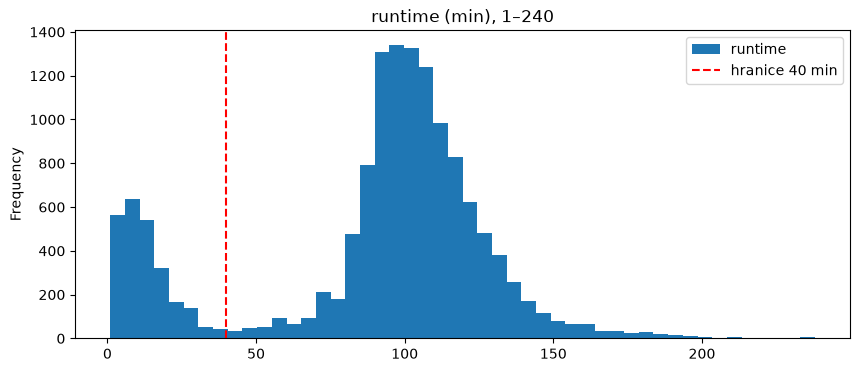

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
df.loc[df["runtime"].between(1, 240), "runtime"].plot.hist(bins=48, ax=ax, title="runtime (min), 1–240")
ax.axvline(40, color="red", linestyle="--", label="hranice 40 min")
ax.legend()
print("podíl filmů s runtime < 40 (vč. 0) podle zdroje (%):")
(df["runtime"] < 40).groupby(df["source"]).mean().mul(100).round(1)

## 7. Rok vydání

nejstarší a nejnovější film v top 10k:

 1902 2026


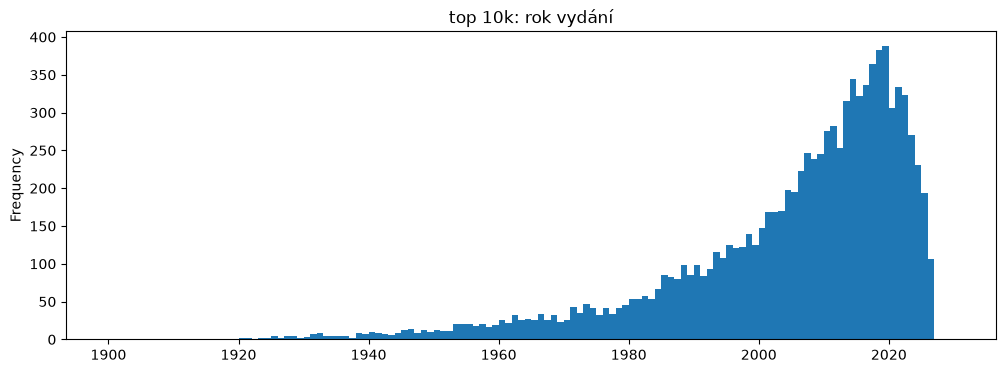

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
df.loc[df["source"] == "top_rated", "year"].plot.hist(bins=range(1900, 2031), ax=ax, title="top 10k: rok vydání")
print("nejstarší a nejnovější film v top 10k:", int(df.loc[df["source"] == "top_rated", "year"].min()),
      int(df.loc[df["source"] == "top_rated", "year"].max()))

## 8. Žánry, jazyky, země původu

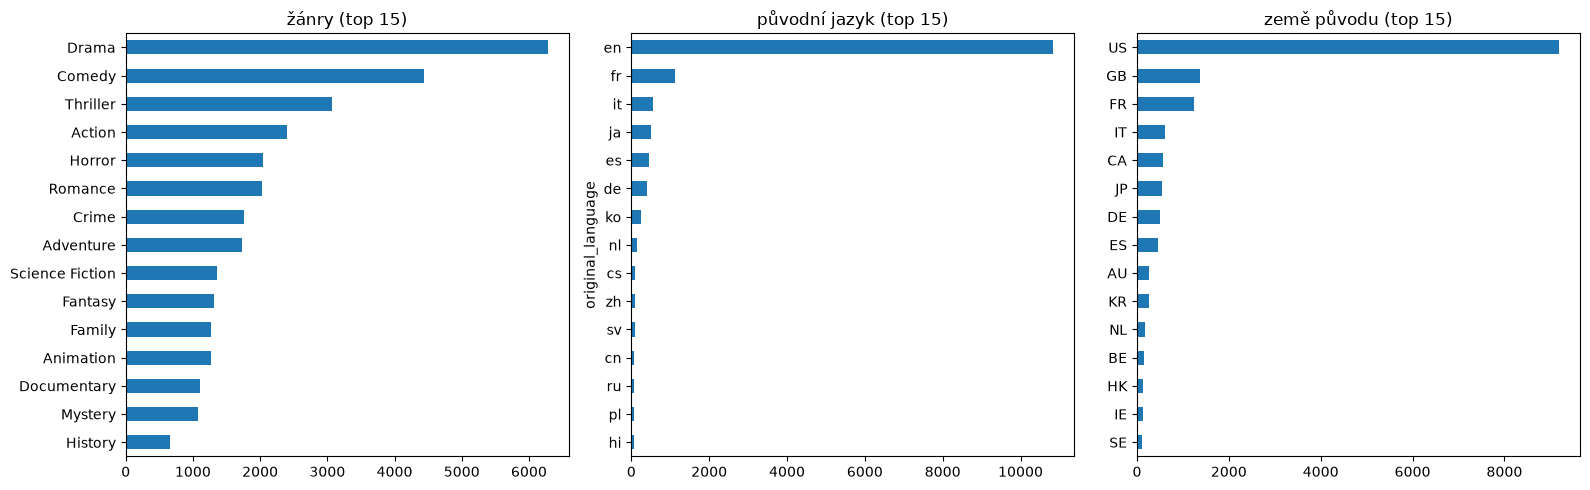

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pd.Series(Counter(g for gs in df["genres"] for g in gs)).nlargest(15).sort_values().plot.barh(ax=axes[0], title="žánry (top 15)")
df["original_language"].value_counts().head(15).sort_values().plot.barh(ax=axes[1], title="původní jazyk (top 15)")
pd.Series(Counter(c for cs in df["origin_country"] for c in cs)).nlargest(15).sort_values().plot.barh(ax=axes[2], title="země původu (top 15)")
plt.tight_layout()

## 9. Status filmu

In [11]:
pd.crosstab(df["status"], df["source"])

source,cinema,cinema+new_release,cinema+new_release+top_rated,cinema+top_rated,new_release,new_release+top_rated,top_rated
status,,,,,,,
Canceled,0,0,0,0,1,0,0
In Production,0,22,0,0,698,0,0
Planned,0,5,0,0,69,0,0
Post Production,4,22,0,0,414,0,0
Released,293,390,2,36,3448,1,9883
Rumored,0,0,0,0,2,0,0


## 10. Premiéra v českých kinech (`release_dates`)

In [12]:
print("filmů s kino premiérou v CZ podle zdroje (%):")
print(df["cz_cinema_date"].notna().groupby(df["source"]).mean().mul(100).round(1))
df.loc[df["source"].str.contains("cinema"), ["title", "release_date", "cz_cinema_date", "source"]] \
  .sort_values("cz_cinema_date", ascending=False).head(10)

filmů s kino premiérou v CZ podle zdroje (%):
source
cinema                          22.2
cinema+new_release              12.3
cinema+new_release+top_rated    50.0
cinema+top_rated                63.9
new_release                      0.6
new_release+top_rated            0.0
top_rated                       28.5
Name: cz_cinema_date, dtype: float64


,title,release_date,cz_cinema_date,source
9978,Fatherland,2026-06-19,2027-01-21,cinema
10498,Gentle Monster,2026-09-17,2027-01-14,cinema
10499,Paper Tiger,2026-11-13,2027-01-07,cinema+new_release
9938,Primetime,2026-09-23,2026-12-03,cinema
10483,Ramayana: Rise of a Legend,2026-11-04,2026-11-26,cinema
10488,Club Kid,2026-11-04,2026-11-19,cinema+new_release
10490,I Play Rocky,2026-11-06,2026-11-19,cinema+new_release
10646,Saul: TICHÉ VODY,2026-11-17,2026-11-17,cinema+new_release
10649,James McNeill Whistler,2026-09-15,2026-11-17,cinema
10485,Ebenezer,2026-11-11,2026-11-12,cinema+new_release


## 11. Velikost záznamu

In [13]:
df.groupby("source")[["kb", "n_cast", "n_crew", "n_keywords"]].mean().round(1)

,kb,n_cast,n_crew,n_keywords
source,,,,
cinema,7.8,8.6,7.5,3.2
cinema+new_release,6.0,5.9,6.1,3.2
cinema+new_release+top_rated,43.2,20.0,24.0,12.5
cinema+top_rated,20.5,18.2,13.6,18.2
new_release,4.1,4.6,4.4,1.6
new_release+top_rated,43.3,20.0,19.0,11.0
top_rated,16.6,18.7,13.1,11.9


## 12. Závěry (běh `full` z 2026-10-26, 15 290 filmů)

**Top 10k (`top_rated`, 9 883 filmů jen z tohoto zdroje) je čistý.**
- Každý film má aspoň 300 hlasů (nejnižší hodnota v datech je 300, takže TMDB používá tento práh), medián 886.
- Popis a plakát mají skoro všechny filmy, herce chybí u 0,2 %, keywords u 3 %.
- `runtime < 40` jen 1,6 % (krátké filmy v žebříčku). `budget = 0` u 31 % a `revenue = 0` u 25 %, což znamená neznámou hodnotu, ne nulu.
- Roky vydání 1902–2026, status je vždy `Released`.

**Novinky (`new_release`, 4 632 filmů jen z tohoto zdroje) jsou z velké části šum.**
- 92,7 % nemá žádný hlas, 99,2 % nemá tržby.
- 69,7 % má `runtime < 40`, z toho 26,3 % délku neznámou (`0`).
- 16 % nemá popis, 19 % plakát, 26 % herce, 68 % keywords.
- Status: 3 448 `Released`, 698 `In Production`, 414 `Post Production`, 69 `Planned`.

**Kina (`now_playing` a `upcoming` US/CZ) obsahují taky hodně šumu.**
- Filmy jen z kin (297): 62 % bez hlasu, 44 % `runtime < 40`. TMDB do `now_playing` zřejmě počítá i limitovaná a festivalová promítání.
- Kino premiéru v CZ (`release_dates`, typ 2 nebo 3) má jen 22 % filmů jen z kin a 12 % filmů z kin a novinek. Většina filmů z US kin do českých kin nepřijde nebo datum ještě není známé.

**Důsledky pro čištění a filtry**
- Top 10k stačí čistit běžně: `0` → `NULL` u `budget`, `revenue` a `runtime`, prázdné stringy → `NULL`.
- U novinek a kin je potřeba filtr na kvalitu. Možnosti: `runtime ≥ 40` (už v API), povinný popis a plakát, minimální popularita nebo počet hlasů. Rozhodnout v BigQuery, případně přesunout do API.
- Pro „co bude v kinech v ČR“ je spolehlivější `release_dates` s CZ datem než samotný seznam `upcoming:CZ`.
- Průměrná velikost záznamu je 12,3 kB (top 10k 16,6 kB, novinky 4,1 kB).

Pozn.: JSONL se musí číst po řádcích `\n`, ne přes `splitlines()`. Texty obsahují znaky jako U+2028, které `splitlines()` bere jako konec řádku.
